# RT-DETR-L — порівняння трьох tuning-експериментів

**Мета:** порівняти `tune_reference` (300 queries, стандартний matching), `tune_queries200` (200 queries) і `tune_matching` (300 queries, змінені matching costs). Завантажуємо `results.csv` із приватного Hugging Face, виводимо метрики для кожної епохи, визначаємо найкращий результат, будуємо графіки і зберігаємо підсумкові файли.

**Важливо:** цей ноутбук **не навчає моделі**, **не потребує GPU**, не перезаписує checkpoints і не запускає зайву evaluation. Метрики тут беруться з *training-monitoring validation* (146 зображень); це **не** повна COCO evaluation на 570 зображеннях. Для підсумкового порівняння з CNN-детекторами потрібно окремо оцінити всі відібрані моделі за єдиним протоколом.

Запуск: **Kaggle → Settings → Internet ON**, Accelerator **None**, secret `HF_TOKEN` (з доступом до приватного репозиторію). Далі **Run All**.

In [1]:
# 1. Підготовка середовища — без ultralytics / GPU
import sys, subprocess, importlib.util
for package, module in [("huggingface_hub", "huggingface_hub"), ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import os
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from huggingface_hub import HfApi, hf_hub_download

HF_REPO = "lilialania/visdrone-retinanet"
WORK = Path("/kaggle/working/rtdetr_tuning_comparison")
WORK.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {
    "tune_reference": {"queries": 300, "matching": {"class": 2, "bbox": 5, "giou": 2}},
    "tune_queries200": {"queries": 200, "matching": {"class": 2, "bbox": 5, "giou": 2}},
    "tune_matching": {"queries": 300, "matching": {"class": 2, "bbox": 7, "giou": 3}},
}
print("Output directory:", WORK)
print("Experiments:", ", ".join(EXPERIMENTS))

Output directory: /kaggle/working/rtdetr_tuning_comparison
Experiments: tune_reference, tune_queries200, tune_matching


In [2]:
# 2. Авторизація приватного Hugging Face repo — єдина змінна HF_TOKEN для всіх комірок
import os
from kaggle_secrets import UserSecretsClient
from huggingface_hub import HfApi

HF_TOKEN = UserSecretsClient().get_secret('HF_TOKEN').strip()
assert HF_TOKEN, 'HF_TOKEN is empty. Enable access to the Kaggle secret in this notebook.'
os.environ['HF_TOKEN'] = HF_TOKEN
token = HF_TOKEN  # сумісність із початковою секцією порівняння
api = HfApi(token=HF_TOKEN)
account = api.whoami()
repo_info = api.repo_info(repo_id=HF_REPO, repo_type='model', token=HF_TOKEN)
print('Authenticated as:', account['name'])
print('Private repository access: OK')
print('Repository:', repo_info.id)


Authenticated as: lilialania
Private repository access: OK
Repository: lilialania/visdrone-retinanet


In [3]:
# 3. Завантажити results.csv всіх 3 експериментів
frames = {}
missing = {}
for name in EXPERIMENTS:
    remote_path = f"query_rtdetr/{name}/results.csv"
    try:
        local_path = hf_hub_download(
            repo_id=HF_REPO,
            filename=remote_path,
            repo_type="model",
            token=token,
        )
        df = pd.read_csv(local_path)
        df.columns = df.columns.astype(str).str.strip()
        if df.empty:
            raise ValueError("CSV is empty")
        frames[name] = df
        print(f"✅ {name}: {len(df)} rows")
    except Exception as exc:
        missing[name] = str(exc)
        print(f"❌ {name}: {exc}")

if missing:
    print("\nMissing files:", json.dumps(missing, indent=2, ensure_ascii=False))
if not frames:
    raise RuntimeError("Не вдалося завантажити жодного results.csv")

# Стовпці першого файлу — зручно для діагностики версій Ultralytics.
print("\nAvailable columns:", list(next(iter(frames.values())).columns))

results.csv:   0%|          | 0.00/653 [00:00<?, ?B/s]

✅ tune_reference: 4 rows


results.csv:   0%|          | 0.00/653 [00:00<?, ?B/s]

✅ tune_queries200: 4 rows


results.csv:   0%|          | 0.00/650 [00:00<?, ?B/s]

✅ tune_matching: 4 rows

Available columns: ['epoch', 'time', 'train/giou_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/giou_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [4]:
# 4. Визначити назви стовпців (різні версії Ultralytics можуть відрізнятися)
def find_metric_column(df, kind):
    cols = list(df.columns)
    if kind == "map5095":
        return next((col for col in cols if "map50-95" in col.lower() or "map50_95" in col.lower()), None)
    if kind == "map50":
        return next((col for col in cols if "map50" in col.lower() and "95" not in col.lower()), None)
    if kind == "precision":
        return next((col for col in cols if "precision" in col.lower() or col.lower().startswith("metrics/p(")), None)
    if kind == "recall":
        return next((col for col in cols if "recall" in col.lower() or col.lower().startswith("metrics/r(")), None)
    return None

records = []
curves = {}
for name, raw in frames.items():
    df = raw.copy()
    metric_col = find_metric_column(df, "map5095")
    map50_col = find_metric_column(df, "map50")
    if metric_col is None:
        print(f"⚠️ {name}: cannot find mAP50-95, columns: {list(df.columns)}")
        continue

    df[metric_col] = pd.to_numeric(df[metric_col], errors="coerce")
    if map50_col:
        df[map50_col] = pd.to_numeric(df[map50_col], errors="coerce")

    if "epoch" in df.columns:
        epochs = pd.to_numeric(df["epoch"], errors="coerce")
        # Ultralytics typically uses 1..N, but do not assume that for all files.
        df["plot_epoch"] = epochs
    else:
        df["plot_epoch"] = range(1, len(df) + 1)

    valid = df.dropna(subset=[metric_col]).copy()
    if valid.empty:
        print(f"⚠️ {name}: no valid mAP50-95 values")
        continue
    best_idx = valid[metric_col].idxmax()
    best = valid.loc[best_idx]
    final = valid.iloc[-1]
    records.append({
        "experiment": name,
        "queries": EXPERIMENTS[name]["queries"],
        "matching_costs": str(EXPERIMENTS[name]["matching"]),
        "epochs_logged": len(df),
        "best_epoch": int(best["plot_epoch"]),
        "best_mAP50_95": float(best[metric_col]),
        "best_epoch_mAP50": float(best[map50_col]) if map50_col and pd.notna(best[map50_col]) else float("nan"),
        "last_epoch_mAP50_95": float(final[metric_col]),
    })
    curves[name] = (df, metric_col, map50_col)

summary = pd.DataFrame(records)
if summary.empty:
    raise RuntimeError("Немає розпізнаних mAP50-95 у завантажених CSV")
summary = summary.sort_values("best_mAP50_95", ascending=False).reset_index(drop=True)
summary.to_csv(WORK / "comparison_summary.csv", index=False)

print("Порівняння за НАЙКРАЩОЮ епохою на training-monitoring validation:")
display(summary.round(5))
print("✅ CSV saved:", WORK / "comparison_summary.csv")

Порівняння за НАЙКРАЩОЮ епохою на training-monitoring validation:


,experiment,queries,matching_costs,epochs_logged,best_epoch,best_mAP50_95,best_epoch_mAP50,last_epoch_mAP50_95
0,tune_matching,300,"{'class': 2, 'bbox': 7, 'giou': 3}",4,1,0.20394,0.38110,0.20117
1,tune_reference,300,"{'class': 2, 'bbox': 5, 'giou': 2}",4,1,0.20349,0.38081,0.20121
2,tune_queries200,200,"{'class': 2, 'bbox': 5, 'giou': 2}",4,1,0.19841,0.36914,0.19697


✅ CSV saved: /kaggle/working/rtdetr_tuning_comparison/comparison_summary.csv


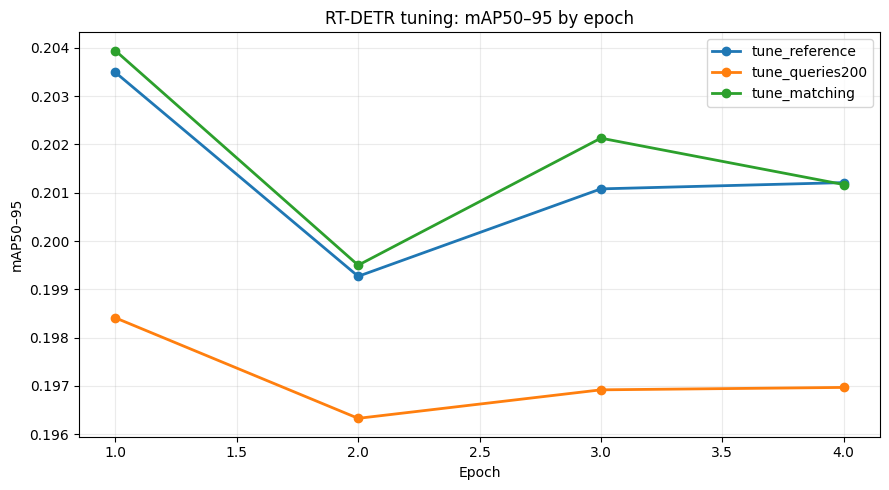

Saved: /kaggle/working/rtdetr_tuning_comparison/map50_95_by_epoch.png


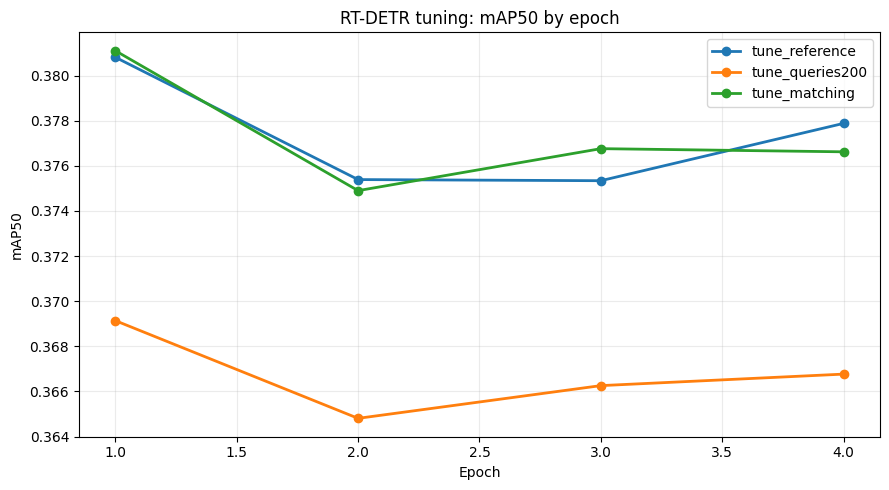

Saved: /kaggle/working/rtdetr_tuning_comparison/map50_by_epoch.png


In [5]:
# 5. Графіки mAP за епохами (зберігаємо у PNG)
def plot_metric(metric_kind, title, filename, ylabel):
    fig, ax = plt.subplots(figsize=(9, 5))
    plotted = 0
    for name, (df, map5095_col, map50_col) in curves.items():
        col = map5095_col if metric_kind == "map5095" else map50_col
        if col is None:
            continue
        values = pd.to_numeric(df[col], errors="coerce")
        ax.plot(df["plot_epoch"], values, marker="o", linewidth=2, label=name)
        plotted += 1
    if plotted == 0:
        plt.close(fig)
        print("Skipped:", filename, "— missing metric")
        return
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    out = WORK / filename
    fig.savefig(out, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved:", out)

plot_metric("map5095", "RT-DETR tuning: mAP50–95 by epoch", "map50_95_by_epoch.png", "mAP50–95")
plot_metric("map50", "RT-DETR tuning: mAP50 by epoch", "map50_by_epoch.png", "mAP50")

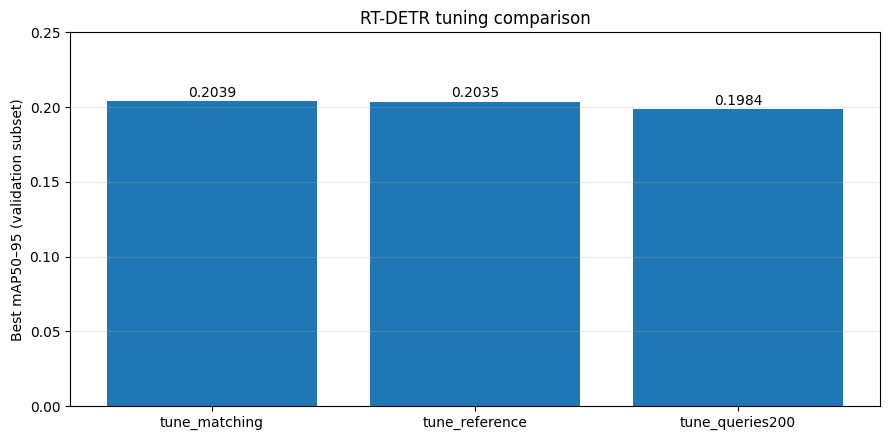

Saved: /kaggle/working/rtdetr_tuning_comparison/best_map_comparison.png


In [6]:
# 6. Порівняння найкращих mAP50–95
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(summary["experiment"], summary["best_mAP50_95"])
ax.set_ylabel("Best mAP50–95 (validation subset)")
ax.set_title("RT-DETR tuning comparison")
ax.set_ylim(0, max(0.25, float(summary["best_mAP50_95"].max()) * 1.18))
for i, val in enumerate(summary["best_mAP50_95"]):
    ax.text(i, float(val) + 0.003, f"{val:.4f}", ha="center")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
out = WORK / "best_map_comparison.png"
fig.savefig(out, dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", out)

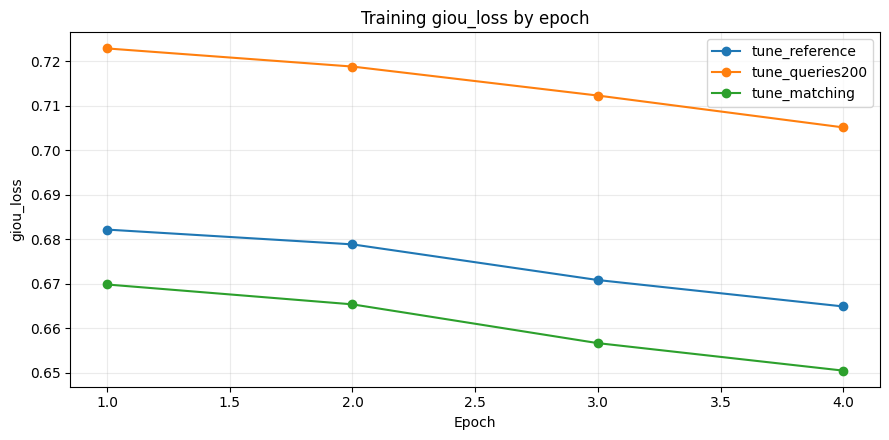

Saved: /kaggle/working/rtdetr_tuning_comparison/giou_loss_by_epoch.png


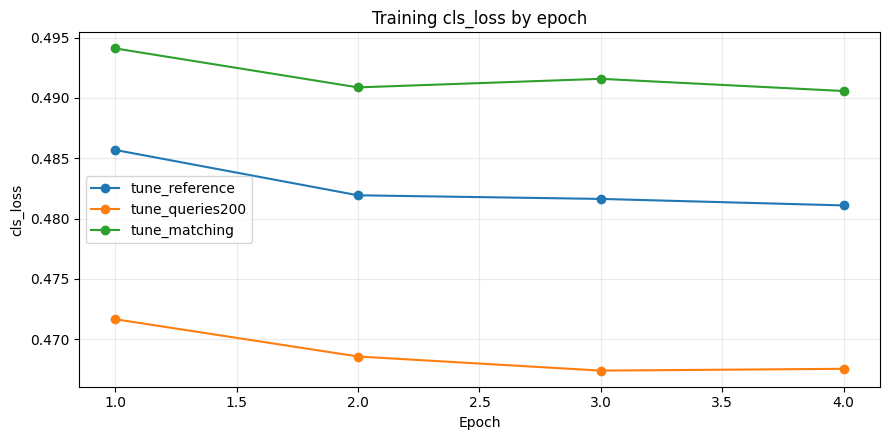

Saved: /kaggle/working/rtdetr_tuning_comparison/cls_loss_by_epoch.png


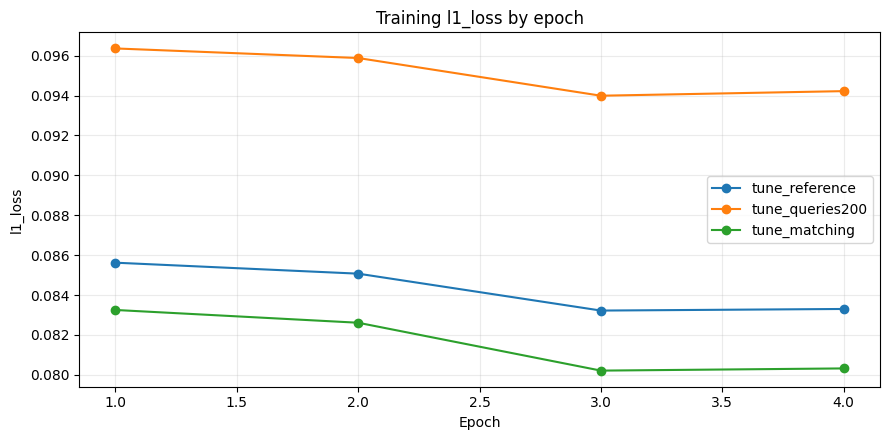

Saved: /kaggle/working/rtdetr_tuning_comparison/l1_loss_by_epoch.png


In [7]:
# 7. Training losses — якщо відповідні стовпці є у CSV
# Малюємо кожну втрату окремим графіком для читабельності.
loss_patterns = {
    "giou_loss": "train/giou_loss",
    "cls_loss": "train/cls_loss",
    "l1_loss": "train/l1_loss",
}
for short_name, pattern in loss_patterns.items():
    fig, ax = plt.subplots(figsize=(9, 4.5))
    plotted = False
    for name, (df, _, _) in curves.items():
        col = next((c for c in df.columns if pattern.lower() in c.lower()), None)
        if col is None:
            continue
        ax.plot(df["plot_epoch"], pd.to_numeric(df[col], errors="coerce"), marker="o", label=name)
        plotted = True
    if plotted:
        ax.set_title(f"Training {short_name} by epoch")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(short_name)
        ax.grid(alpha=0.25)
        ax.legend()
        fig.tight_layout()
        out = WORK / f"{short_name}_by_epoch.png"
        fig.savefig(out, dpi=180, bbox_inches="tight")
        plt.show()
        print("Saved:", out)
    else:
        plt.close(fig)
        print("No columns found for", short_name)

In [8]:
# 8. Автоматичний висновок і метадані для звіту
winner = summary.iloc[0]
runner_up = summary.iloc[1] if len(summary) > 1 else None
report_lines = [
    "RT-DETR-L query-specific tuning: comparative analysis",
    "",
    "Protocol: monitoring validation subset (146 images); NOT full COCO evaluation.",
    "Source: Hugging Face results.csv in lilialania/visdrone-retinanet.",
    "Model: RT-DETR-L; same start checkpoint finetune_safe/weights/best.pt.",
    "Hyperparameters: 4 epochs, AdamW, lr=1e-5, batch=1, image size=640.",
    "",
    "Best result by maximum epoch mAP50-95:",
    f"  {winner['experiment']} | epoch {int(winner['best_epoch'])} | mAP50-95={winner['best_mAP50_95']:.5f}",
]
if runner_up is not None:
    report_lines.append(
        f"  Margin vs second: {winner['best_mAP50_95'] - runner_up['best_mAP50_95']:+.5f} mAP50-95"
    )
report_lines += [
    "",
    "Caution: a small difference on a 146-image subset is not proof of meaningful improvement.",
    "Next step: evaluate the selected checkpoints using the same full-validation COCO evaluation protocol as other detectors.",
]
report = "\n".join(report_lines)
(WORK / "comparison_notes.txt").write_text(report, encoding="utf-8")
(WORK / "comparison_summary.json").write_text(
    summary.to_json(orient="records", force_ascii=False, indent=2), encoding="utf-8"
)
print(report)

RT-DETR-L query-specific tuning: comparative analysis

Protocol: monitoring validation subset (146 images); NOT full COCO evaluation.
Source: Hugging Face results.csv in lilialania/visdrone-retinanet.
Model: RT-DETR-L; same start checkpoint finetune_safe/weights/best.pt.
Hyperparameters: 4 epochs, AdamW, lr=1e-5, batch=1, image size=640.

Best result by maximum epoch mAP50-95:
  tune_matching | epoch 1 | mAP50-95=0.20394
  Margin vs second: +0.00045 mAP50-95

Caution: a small difference on a 146-image subset is not proof of meaningful improvement.
Next step: evaluate the selected checkpoints using the same full-validation COCO evaluation protocol as other detectors.


## 10. Повна COCO evaluation готових RT-DETR checkpoints (GPU, без навчання)

Ця секція **окрема від аналізу `results.csv`**. Вона завантажує готові ваги з Hugging Face, бере **оригінальний VisDrone validation COCO** і використовує однаковий pipeline (`src.models.tiled_yolo.sliced_predict`) для всіх трьох моделей: повне зображення + (опційно) перекривні tiles, потім NMS між tiles. Зберігаються **mAP50–95, AP50, AP75, AP_small, AP_medium, AP_large, час інференсу** та JSON метрик.

**Перед запуском GPU-частини:** Kaggle → Settings → **Accelerator GPU** (достатньо T4), Internet ON, секрет `HF_TOKEN` увімкнений, і **Add Input** → competition dataset `Multiple Object Video Detection | HW2 | UCU AI 2026` (доступ до змагання необхідний). Потім у наступній комірці встанови `RUN_COCO_EVAL = True`.

- `EVAL_STEP=1` — **усі зображення** початкового validation set (справжня повна evaluation).
- `EVAL_STEP=5` — кожен п'ятий кадр (зазвичай ~570), **не повний** val, але швидше; для порівняння з попередньою оцінкою використай той самий step, tile, imgsz, conf.
- `EVAL_TILE=0` — тільки full-image pass, як у попередньому бюджетному RT-DETR evaluation; `640` — sliced inference, повільніше. Не порівнюй результати різних протоколів як одне й те саме.

**Жодна комірка не викликає `.train()`.** Якщо checkpoint `tune_reference/epoch_04.pt` містить несумісний серіалізований метод, модель буде позначена як failed, а не підмінена іншою моделлю. Для коректного порівняння можна використати відновлений checkpoint, якщо окремо завантажити його на Hugging Face.

In [9]:
# 10A. COCO EVALUATION CONFIG — відредагуй тільки тут
RUN_COCO_EVAL = True  # постав True ПІСЛЯ увімкнення GPU та підключення competition dataset
EVAL_STEP = 1          # 1 = ALL val frames; 5 = every fifth frame (~570 у попередньому протоколі)
EVAL_TILE = 0          # 0 = full-image only; 640 = tile + full-image
EVAL_FULL_IMGSZ = 640 # повинен збігатися для всіх трьох моделей
EVAL_CONF = 0.01
EVAL_MAX_DET = 500     # значення береться з репозиторію; тут лише опис протоколу

DATA_ROOT = Path('/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026')
REPO = Path('/kaggle/working/drone-multi-object-detection')
REPO_URL = 'https://github.com/lilialania/drone-multi-object-detection.git'
EVAL_OUT = WORK / f'coco_eval_step{EVAL_STEP}_tile{EVAL_TILE}_imgsz{EVAL_FULL_IMGSZ}'
EVAL_OUT.mkdir(parents=True, exist_ok=True)

# Пріоритет best.pt; reference має fallback на останній epoch checkpoint.
CHECKPOINT_CANDIDATES = {
    'tune_reference': [
        'query_rtdetr/tune_reference/weights/best.pt',
        'query_rtdetr/tune_reference/epoch_04.pt',
    ],
    'tune_queries200': ['query_rtdetr/tune_queries200/weights/best.pt'],
    'tune_matching': ['query_rtdetr/tune_matching/weights/best.pt'],
}
print('Evaluation enabled:', RUN_COCO_EVAL)
print('Protocol:', dict(step=EVAL_STEP, tile=EVAL_TILE, imgsz=EVAL_FULL_IMGSZ, conf=EVAL_CONF))
if not RUN_COCO_EVAL:
    print('Training-history analysis is complete. To run COCO evaluation, enable GPU and set RUN_COCO_EVAL=True.')

Evaluation enabled: True
Protocol: {'step': 1, 'tile': 0, 'imgsz': 640, 'conf': 0.01}


In [10]:
# 10B. Перевірка середовища; виконувати на GPU тільки якщо RUN_COCO_EVAL=True
if RUN_COCO_EVAL:
    import torch
    assert torch.cuda.is_available(), 'Увімкни Kaggle Accelerator → GPU'
    assert EVAL_STEP >= 1 and EVAL_TILE >= 0 and EVAL_FULL_IMGSZ > 0
    assert (DATA_ROOT / 'val' / 'annotations_coco.json').is_file(), (
        f'Не знайдено {DATA_ROOT / "val" / "annotations_coco.json"}. '
        'Підключи датасет competition у Add Input.'
    )
    # Встановлюємо саме версію з навчання до імпорту Ultralytics.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.210', 'pycocotools'])
    if not (REPO / 'src' / 'tiled_yolo.py').exists():
        subprocess.check_call(['git', 'clone', REPO_URL, str(REPO)])
    # Звірка масштабу evaluation із тим, що є в COCO анотаціях
    coco_meta = json.loads((DATA_ROOT / 'val' / 'annotations_coco.json').read_text())
    all_images = sorted(im['id'] for im in coco_meta['images'])
    eval_ids = all_images[::EVAL_STEP]
    print('GPU:', torch.cuda.get_device_name(0))
    print(f'Images in original validation: {len(all_images)}; selected for evaluation: {len(eval_ids)}')
    print('Repo:', REPO)
else:
    print('GPU preflight skipped.')

Cloning into '/kaggle/working/drone-multi-object-detection'...


GPU: Tesla T4
Images in original validation: 2846; selected for evaluation: 2846
Repo: /kaggle/working/drone-multi-object-detection


In [11]:
# 10C. Запис окремого evaluation runner (в окремому процесі для кожної моделі)
# Runner використовує репозиторний sliced_predict і pycocotools; не тренує модель.
EVAL_SCRIPT = WORK / 'evaluate_one_rtdetr.py'
EVAL_SCRIPT.write_text(r'''import argparse, json, time
from pathlib import Path
import numpy as np
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import RTDETR
from src.models.tiled_yolo import sliced_predict
from src.data_utils import image_path_for
from src.models.yolo_baseline import MAX_DETECTIONS

p=argparse.ArgumentParser()
p.add_argument('--weights', required=True)
p.add_argument('--split-root', required=True)
p.add_argument('--out', required=True)
p.add_argument('--step',type=int,default=1)
p.add_argument('--tile',type=int,default=0)
p.add_argument('--imgsz',type=int,default=640)
p.add_argument('--conf',type=float,default=.01)
a=p.parse_args()
coco=COCO(str(Path(a.split_root)/'annotations_coco.json'))
image_ids=sorted(coco.getImgIds())[::a.step]
model=RTDETR(a.weights)
results=[]
seconds=0.0
for i,image_id in enumerate(image_ids):
    tick=time.perf_counter()
    boxes,scores,classes=sliced_predict(
        model,image_path_for(Path(a.split_root),coco.imgs[image_id]['file_name']),
        a.tile,0.2,a.imgsz,a.conf)
    elapsed=time.perf_counter()-tick
    if i: seconds+=elapsed # first image is warm-up
    for (x1,y1,x2,y2),score,cls in zip(boxes,scores,classes):
        results.append({'image_id':int(image_id),'category_id':int(cls)+1,
                        'bbox':[float(x1),float(y1),float(x2-x1),float(y2-y1)],
                        'score':float(score)})
    if (i+1)%100==0 or i+1==len(image_ids):
        print(f'Predicted {i+1}/{len(image_ids)}',flush=True)
if not results: raise RuntimeError('No predictions produced; cannot evaluate')
ev=COCOeval(coco,coco.loadRes(results),'bbox')
ev.params.imgIds=image_ids
ev.params.maxDets=[1,100,MAX_DETECTIONS]
ev.evaluate();ev.accumulate();ev.summarize()
# Extract AP from maxDet=MAX_DETECTIONS using same precision tensor as src.models.faster_rcnn.coco_map
pr=ev.eval['precision'][...,-1] # [IoU, recall, class, area]
def ap(a):
    v=a[a>-1]
    return float(v.mean()) if len(v) else float('nan')
metrics={
    'mAP50_95':ap(pr[:,:,:,0]),
    'AP50':ap(pr[0,:,:,0]),
    'AP75':ap(pr[5,:,:,0]),
    'AP_small':ap(pr[:,:,:,1]),
    'AP_medium':ap(pr[:,:,:,2]),
    'AP_large':ap(pr[:,:,:,3]),
    'ms_per_image':(1000*seconds/(len(image_ids)-1)) if len(image_ids)>1 else float('nan'),
    'images_evaluated':len(image_ids),
    'detections':len(results),
    'step':a.step,'tile':a.tile,'imgsz':a.imgsz,'conf':a.conf,
    'max_detections':MAX_DETECTIONS,
}
Path(a.out).write_text(json.dumps(metrics,indent=2),encoding='utf-8')
print('METRICS_JSON:',json.dumps(metrics),flush=True)
''', encoding='utf-8')
print('Prepared:',EVAL_SCRIPT)

Prepared: /kaggle/working/rtdetr_tuning_comparison/evaluate_one_rtdetr.py


In [12]:
# 10D. Оцінювання всіх checkpoint по черзі; результат кожного зберігається одразу
# Повторний запуск пропускає готові JSON за тим самим протоколом.
if RUN_COCO_EVAL:
    import traceback
    full_eval_status = {}
    for experiment, candidates in CHECKPOINT_CANDIDATES.items():
        dest = EVAL_OUT / f'{experiment}.json'
        logfile = EVAL_OUT / f'{experiment}.log'
        if dest.is_file():
            print('Already evaluated:',experiment)
            full_eval_status[experiment] = 'already_done'
            continue
        print('\n--- COCO EVALUATION:',experiment,'---',flush=True)
        weight = None
        for filename in candidates:
            try:
                weight = hf_hub_download(repo_id=HF_REPO,filename=filename,repo_type='model',token=HF_TOKEN)
                print('Checkpoint:',filename)
                break
            except Exception as exc:
                print('Candidate not available:',filename, type(exc).__name__)
        if weight is None:
            full_eval_status[experiment] = 'checkpoint_missing'
            print('Skipping; no checkpoint accessible:',experiment)
            continue
        cmd = [sys.executable,'-u',str(EVAL_SCRIPT),
               '--weights',str(weight),'--split-root',str(DATA_ROOT/'val'),
               '--out',str(dest),'--step',str(EVAL_STEP),'--tile',str(EVAL_TILE),
               '--imgsz',str(EVAL_FULL_IMGSZ),'--conf',str(EVAL_CONF)]
        # Зробити імпорт src доступним для зовнішнього процесу
        env = os.environ.copy()
        env['PYTHONPATH'] = str(REPO) + os.pathsep + env.get('PYTHONPATH','')
        with logfile.open('w',encoding='utf-8') as log:
            process = subprocess.run(cmd,stdout=log,stderr=subprocess.STDOUT,env=env)
        if process.returncode != 0:
            full_eval_status[experiment] = 'failed'
            print('EVALUATION FAILED:',experiment,'see',logfile)
            print(logfile.read_text(encoding='utf-8',errors='replace')[-1800:])
            continue
        full_eval_status[experiment] = 'ok'
        print('Saved:',dest)
    (EVAL_OUT/'statuses.json').write_text(json.dumps(full_eval_status,indent=2))
    print('Finished:',full_eval_status)
else:
    print('COCO evaluation skipped (RUN_COCO_EVAL=False).')


--- COCO EVALUATION: tune_reference ---
Candidate not available: query_rtdetr/tune_reference/weights/best.pt RemoteEntryNotFoundError


query_rtdetr/tune_reference/epoch_04.pt: reconstructing file:   0%|          |  0.00B /  329MB            

query_rtdetr/tune_reference/epoch_04.pt: downloading bytes:           |  0.00B            

Checkpoint: query_rtdetr/tune_reference/epoch_04.pt
EVALUATION FAILED: tune_reference see /kaggle/working/rtdetr_tuning_comparison/coco_eval_step1_tile0_imgsz640/tune_reference.log
/lib/python3.13/dist-packages/ultralytics/models/rtdetr/model.py", line 51, in __init__
    super().__init__(model=model, task="detect")
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/model.py", line 140, in __init__
    self._load(model, task=task)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/model.py", line 255, in _load
    self.model, self.ckpt = load_checkpoint(weights)
                            ~~~~~~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/nn/tasks.py", line 2012, in load_checkpoint
    ckpt, weight = torch_safe_load(weight)  # load ckpt
                   ~~~~~~~~~~~~~~~^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/n

query_rtdetr/tune_queries200/weights/bes(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr/tune_queries200/weights/bes(…): downloading bytes:           |  0.00B            

Checkpoint: query_rtdetr/tune_queries200/weights/best.pt
Saved: /kaggle/working/rtdetr_tuning_comparison/coco_eval_step1_tile0_imgsz640/tune_queries200.json

--- COCO EVALUATION: tune_matching ---


query_rtdetr/tune_matching/weights/best.(…): reconstructing file:   0%|          |  0.00B / 66.2MB            

query_rtdetr/tune_matching/weights/best.(…): downloading bytes:           |  0.00B            

Checkpoint: query_rtdetr/tune_matching/weights/best.pt
Saved: /kaggle/working/rtdetr_tuning_comparison/coco_eval_step1_tile0_imgsz640/tune_matching.json
Finished: {'tune_reference': 'failed', 'tune_queries200': 'ok', 'tune_matching': 'ok'}


,experiment,mAP50_95,AP50,AP75,AP_small,AP_medium,AP_large,ms_per_image,images_evaluated,detections,step,tile,imgsz,conf,max_detections
0,tune_matching,0.20329,0.38792,0.18500,0.05306,0.18857,0.35053,85.63331,2846,685342,1,0,640,0.01,500
1,tune_queries200,0.19804,0.37596,0.18149,0.05141,0.18344,0.33985,97.05165,2846,475085,1,0,640,0.01,500


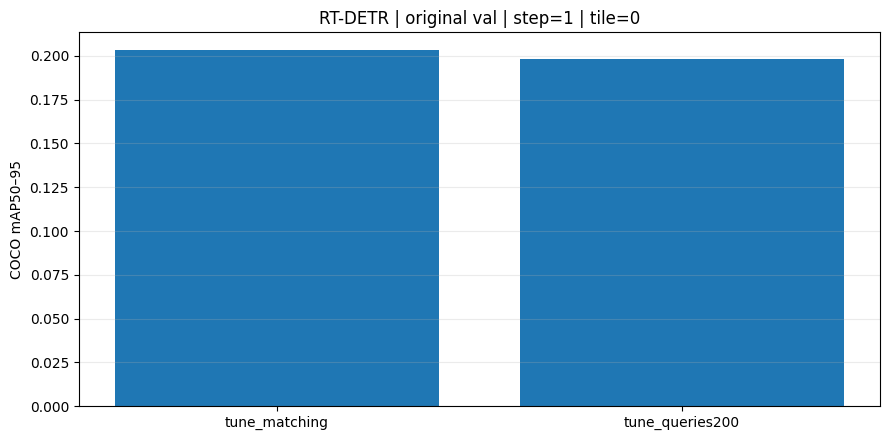

COCO comparison saved: /kaggle/working/rtdetr_tuning_comparison/coco_eval_step1_tile0_imgsz640/coco_metrics_comparison.csv


In [13]:
# 10E. Повна таблиця COCO метрик і графік (лише на основі виконаних оцінок)
metric_files = sorted(EVAL_OUT.glob('tune_*.json'))
full_rows=[]
for p in metric_files:
    values=json.loads(p.read_text(encoding='utf-8'))
    full_rows.append({'experiment':p.stem,**values})
if full_rows:
    full_df=pd.DataFrame(full_rows).sort_values('mAP50_95',ascending=False)
    display(full_df.round(5))
    csv_path=EVAL_OUT/'coco_metrics_comparison.csv'
    full_df.to_csv(csv_path,index=False)
    fig,ax=plt.subplots(figsize=(9,4.5))
    ax.bar(full_df['experiment'],full_df['mAP50_95'])
    ax.set(ylabel='COCO mAP50–95',title=f'RT-DETR | original val | step={EVAL_STEP} | tile={EVAL_TILE}')
    ax.grid(axis='y',alpha=.25)
    fig.tight_layout()
    fig.savefig(EVAL_OUT/'coco_map_comparison.png',dpi=180,bbox_inches='tight')
    plt.show()
    print('COCO comparison saved:',csv_path)
else:
    print('No full evaluation results yet. This is expected with RUN_COCO_EVAL=False.')

### Як інтерпретувати COCO результати

- `comparison_summary.csv` вище — **training-monitoring** оцінка на 146 зображеннях; вона допомагає порівнювати конфігурації за епохами.
- `coco_eval_step*/coco_metrics_comparison.csv` — **COCOeval** на оригінальному validation split за явно вказаними параметрами (`step`, `tile`, `imgsz`, `conf`). AP_small / medium / large використовують стандартні COCO границі площі bounding box.
- Вибирай переможця за mAP50–95 тільки серед моделей, оцінених **за однаковим протоколом**. Для порівняння з RetinaNet/Faster R-CNN потрібно збігатися і за `step`, і за inference procedure (slicing чи повне зображення), і за списком кадрів, category mapping та maxDets.
- **Застереження:** `tune_reference` може мати лише `epoch_04.pt`, а не `best.pt`, і саме цей старий checkpoint раніше потребував відновлення. Якщо він не завантажиться коректно, статус буде `failed`; результати для нього не підміняємо. Також `epoch_04.pt` — не обов'язково найкраща епоха.

У файлі `*.log` є діагностика кожного GPU запуску. GPU evaluation — це новий inference, але **не нове навчання**.

In [14]:
# 11. Повний ZIP усіх створених файлів (включно з COCO-метриками, якщо є)
from zipfile import ZipFile, ZIP_DEFLATED
zip_path = Path('/kaggle/working/rtdetr_tuning_comparison.zip')
with ZipFile(zip_path,'w',ZIP_DEFLATED) as zf:
    for p in sorted(WORK.rglob('*')):
        if p.is_file():
            zf.write(p,arcname=str(p.relative_to(WORK)))
print('ZIP:',zip_path)
print('Size MB:',round(zip_path.stat().st_size/1024**2,2))
print('Training was NOT run.')

ZIP: /kaggle/working/rtdetr_tuning_comparison.zip
Size MB: 0.44
Training was NOT run.


### Що скачати з Kaggle Output

`rtdetr_tuning_comparison.zip` містить попередні графіки трьох експериментів та, **якщо GPU evaluation увімкнено й виконано**, теку `coco_eval_step.../` з порівняльною таблицею COCO, графіком та логами. Після виконання натисни **Save Version → Save & Run All** з GPU для збереження цих результатів у версії Kaggle. Перезапуск з `RUN_COCO_EVAL=False` не запускає оцінювання.